In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns",None)
pd.set_option("display.float_format","{:.2f}".format)

In [2]:
PROJECT_ROOT = Path.cwd().parent

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "SkyCity Auckland Restaurants & Bars.csv"

df = pd.read_csv(DATA_PATH)

In [3]:
df.head()

,CuisineType,RestaurantID,RestaurantName,Segment,Subregion,GrowthFactor,AOV,MonthlyOrders,InStoreOrders,InStoreRevenue,UberEatsOrders,DoorDashOrders,SelfDeliveryOrders,UberEatsRevenue,DoorDashRevenue,SelfDeliveryRevenue,COGSRate,OPEXRate,CommissionRate,DeliveryRadiusKM,DeliveryCostPerOrder,SD_DeliveryTotalCost,InStoreNetProfit,UberEatsNetProfit,DoorDashNetProfit,SelfDeliveryNetProfit,InStoreShare,UE_share,DD_share,SD_share
0,Burgers,25731,Urban Burgers House,Cafe,North Shore,1.03,43.97,668,197,8662.09,212,118,141,9321.64,5188.46,6199.77,0.21,0.37,0.28,11,3.25,458.25,3682.14,1352.45,752.78,2177.19,0.42,0.45,0.25,0.30
1,Burgers,25123,Urban Burgers Diner,QSR,South Auckland,1.05,40.45,1388,259,10476.55,508,282,339,20548.60,11406.90,13712.55,0.25,0.41,0.28,16,4.72,1600.08,3605.72,1318.61,731.99,3119.38,0.23,0.45,0.25,0.30
2,Burgers,25177,King Burgers Eatery,Cafe,West Auckland,1.04,40.03,1717,524,20975.72,537,298,358,21496.11,11928.94,14330.74,0.22,0.41,0.30,11,3.25,1163.50,7810.95,1555.90,863.42,4172.99,0.44,0.45,0.25,0.30
3,Burgers,25540,Classic Burgers Tavern,QSR,North Shore,1.03,36.28,1083,216,7836.48,390,217,260,14149.20,7872.76,9432.80,0.24,0.44,0.33,3,0.89,231.40,2546.02,-72.25,-40.20,2833.26,0.25,0.45,0.25,0.30
4,Burgers,25258,Lucky Burgers Bistro,Cafe,South Auckland,1.05,34.34,1230,261,8962.74,436,242,291,14972.24,8310.28,9992.94,0.22,0.43,0.33,9,2.66,774.06,3093.09,226.17,125.53,2674.56,0.27,0.45,0.25,0.30


In [4]:
print("Dataset shape:",df.shape)
print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (1696, 30)

Column names:
['CuisineType', 'RestaurantID', 'RestaurantName', 'Segment', 'Subregion', 'GrowthFactor', 'AOV', 'MonthlyOrders', 'InStoreOrders', 'InStoreRevenue', 'UberEatsOrders', 'DoorDashOrders', 'SelfDeliveryOrders', 'UberEatsRevenue', 'DoorDashRevenue', 'SelfDeliveryRevenue', 'COGSRate', 'OPEXRate', 'CommissionRate', 'DeliveryRadiusKM', 'DeliveryCostPerOrder', 'SD_DeliveryTotalCost', 'InStoreNetProfit', 'UberEatsNetProfit', 'DoorDashNetProfit', 'SelfDeliveryNetProfit', 'InStoreShare', 'UE_share', 'DD_share', 'SD_share']


In [5]:
print("Data types and non-null counts:","\n")
df.info()

Data types and non-null counts: 

<class 'pandas.DataFrame'>
RangeIndex: 1696 entries, 0 to 1695
Data columns (total 30 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   CuisineType            1696 non-null   str    
 1   RestaurantID           1696 non-null   int64  
 2   RestaurantName         1696 non-null   str    
 3   Segment                1696 non-null   str    
 4   Subregion              1696 non-null   str    
 5   GrowthFactor           1696 non-null   float64
 6   AOV                    1696 non-null   float64
 7   MonthlyOrders          1696 non-null   int64  
 8   InStoreOrders          1696 non-null   int64  
 9   InStoreRevenue         1696 non-null   float64
 10  UberEatsOrders         1696 non-null   int64  
 11  DoorDashOrders         1696 non-null   int64  
 12  SelfDeliveryOrders     1696 non-null   int64  
 13  UberEatsRevenue        1696 non-null   float64
 14  DoorDashRevenue        1696 non-n

In [6]:
quality_report = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2),
    "Unique Values": df.nunique(),
})

display(quality_report)
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate Restuarnat IDs:", df["RestaurantID"].duplicated().sum())

,Data Type,Missing Values,Missing Percentage,Unique Values
CuisineType,str,0,0.00,8
RestaurantID,int64,0,0.00,1696
RestaurantName,str,0,0.00,256
Segment,str,0,0.00,4
Subregion,str,0,0.00,4
GrowthFactor,float64,0,0.00,4
AOV,float64,0,0.00,1064
MonthlyOrders,int64,0,0.00,1024
InStoreOrders,int64,0,0.00,515
InStoreRevenue,float64,0,0.00,1690


Duplicate rows: 0
Duplicate Restuarnat IDs: 0


In [7]:
numeric_df = df.select_dtypes(include = np.number)

display(numeric_df.describe().T)

print("Negative value in order counts:")
order_cols = [
    "MonthlyOrders",
    "InStoreOrders",
    "UberEatsOrders",
    "DoorDashOrders",
    "SelfDeliveryOrders"
]

display((df[order_cols] < 0).sum().rename("Negative Count"))

,count,mean,std,min,25%,50%,75%,max
RestaurantID,1696.00,25848.50,489.74,25001.00,25424.75,25848.50,26272.25,26696.00
GrowthFactor,1696.00,1.03,0.02,0.99,1.03,1.04,1.05,1.05
AOV,1696.00,38.52,4.46,29.79,34.79,38.34,42.50,47.23
MonthlyOrders,1696.00,1190.53,422.33,441.00,827.00,1182.00,1525.00,2337.00
InStoreOrders,1696.00,218.98,149.76,13.00,101.00,178.00,307.00,819.00
InStoreRevenue,1696.00,8422.39,5851.23,412.36,3904.34,6791.43,11550.76,35356.23
UberEatsOrders,1696.00,471.91,171.78,142.00,331.00,456.00,602.00,937.00
DoorDashOrders,1696.00,257.16,92.61,81.00,179.75,249.00,326.25,466.00
SelfDeliveryOrders,1696.00,242.49,129.95,60.00,146.00,212.00,306.25,702.00
UberEatsRevenue,1696.00,18170.03,6959.24,5050.95,12524.74,17548.98,23016.00,43038.96


Negative value in order counts:


MonthlyOrders         0
InStoreOrders         0
UberEatsOrders        0
DoorDashOrders        0
SelfDeliveryOrders    0
Name: Negative Count, dtype: int64

In [8]:
df["CalculatedMonthlyOrders"] = df[
    ["InStoreOrders", "UberEatsOrders",
     "DoorDashOrders","SelfDeliveryOrders"]
].sum(axis=1)

df["OrderCountDifference"] = (
    df["MonthlyOrders"] - df["CalculatedMonthlyOrders"]
)

print("Restaurants with inconsistent order counts:",
    (df["OrderCountDifference"] != 0).sum() 
)

display(
    df.loc[
        df["OrderCountDifference"] != 0,
        ["RestaurantID", "MonthlyOrders",
         "CalculatedMonthlyOrders", "OrderCountDifference"]
    ].head(10)
)

Restaurants with inconsistent order counts: 0


,RestaurantID,MonthlyOrders,CalculatedMonthlyOrders,OrderCountDifference


In [9]:
revenue_cols = [
    "InStoreRevenue",
    "UberEatsRevenue",
    "DoorDashRevenue",
    "SelfDeliveryRevenue"
]

df["CalculatedTotalRevenue"] = df[revenue_cols].sum(axis=1)

df["CalculatedAOV"] = (
    df["CalculatedTotalRevenue"] / df["MonthlyOrders"]
)

df["AOVDifference"] = df["AOV"] - df["CalculatedAOV"]

print(
    "Restaurent with AOV mismatch:",
    (df["AOVDifference"].abs() > 0.01).sum()
)

display(
    df[["RestaurantID", "AOV", "CalculatedAOV", "AOVDifference"]].head()
)

Restaurent with AOV mismatch: 0


,RestaurantID,AOV,CalculatedAOV,AOVDifference
0,25731,43.97,43.97,0.00
1,25123,40.45,40.45,0.00
2,25177,40.03,40.03,-0.00
3,25540,36.28,36.28,-0.00
4,25258,34.34,34.34,0.00


In [10]:
df["ExpectedInStoreProfit"] = (
    df["InStoreRevenue"] * (1- df["COGSRate"] - df["OPEXRate"])
)

df["ExpectedUberEatsProfit"] = (
    df["UberEatsRevenue"] * (1-df["COGSRate"] - df["OPEXRate"] - df["CommissionRate"])
)

df["ExpectedDoorDashProfit"] = (
    df["DoorDashRevenue"] 
    * (1- df["COGSRate"] - df["OPEXRate"] - df["CommissionRate"])
)

df["ExpectedSelfDeliveryProfit"] = (
    df["SelfDeliveryRevenue"]
    * (1- df["COGSRate"] - df["OPEXRate"])
    - df["SD_DeliveryTotalCost"]
)

profit_checks = {
    "Instore": ("InStoreNetProfit", "ExpectedInStoreProfit"),
    "UberEats": ("UberEatsNetProfit", "ExpectedUberEatsProfit"),
    "DoorDash": ("DoorDashNetProfit", "ExpectedDoorDashProfit"),
    "SelfDelivery": ("SelfDeliveryNetProfit", "ExpectedSelfDeliveryProfit")
}

results = []

for channel, (actual_col, expected_col) in profit_checks.items():
    difference = df[actual_col] - df[expected_col]
    
    results.append({
        "Channel": channel,
        "Mean Absolute Difference": difference.abs().mean(),
        "Maximun Absolute Difference": difference.abs().max(),
        "Rows within $0.01": (difference.abs() <= 0.01).sum(),
        "Formula valid" : (difference.abs() <= 0.01).all()
    })
    
profit_validation = pd.DataFrame(results)
display(profit_validation)

,Channel,Mean Absolute Difference,Maximun Absolute Difference,Rows within $0.01,Formula valid
0,Instore,0.00,0.00,1696,True
1,UberEats,0.00,0.00,1696,True
2,DoorDash,0.00,0.00,1696,True
3,SelfDelivery,0.00,0.00,1696,True


In [11]:
delivery_share_cols = ["UE_share", "DD_share", "SD_share"]

df["CalculatedDeliveryShareTotal"] = df[
    delivery_share_cols
].sum(axis=1)

print(
    "Delivery-share totals equal to 1:",
    np.isclose(
        df["CalculatedDeliveryShareTotal"], 1.0,
        atol= 0.01
    ).sum(),
    "out of", len(df)
)

display(
    df[[
        "RestaurantID", "InStoreShare",
        "UE_share", "DD_share", "SD_share",
        "CalculatedDeliveryShareTotal"
    ]].head(10)
)

Delivery-share totals equal to 1: 1696 out of 1696


,RestaurantID,InStoreShare,UE_share,DD_share,SD_share,CalculatedDeliveryShareTotal
0,25731,0.42,0.45,0.25,0.30,1.00
1,25123,0.23,0.45,0.25,0.30,1.00
2,25177,0.44,0.45,0.25,0.30,1.00
3,25540,0.25,0.45,0.25,0.30,1.00
4,25258,0.27,0.45,0.25,0.30,1.00
5,26138,0.24,0.45,0.25,0.30,1.00
6,25396,0.25,0.45,0.25,0.30,1.00
7,25087,0.10,0.45,0.25,0.30,1.00
8,25125,0.33,0.45,0.25,0.30,1.00
9,25762,0.29,0.45,0.25,0.30,1.00


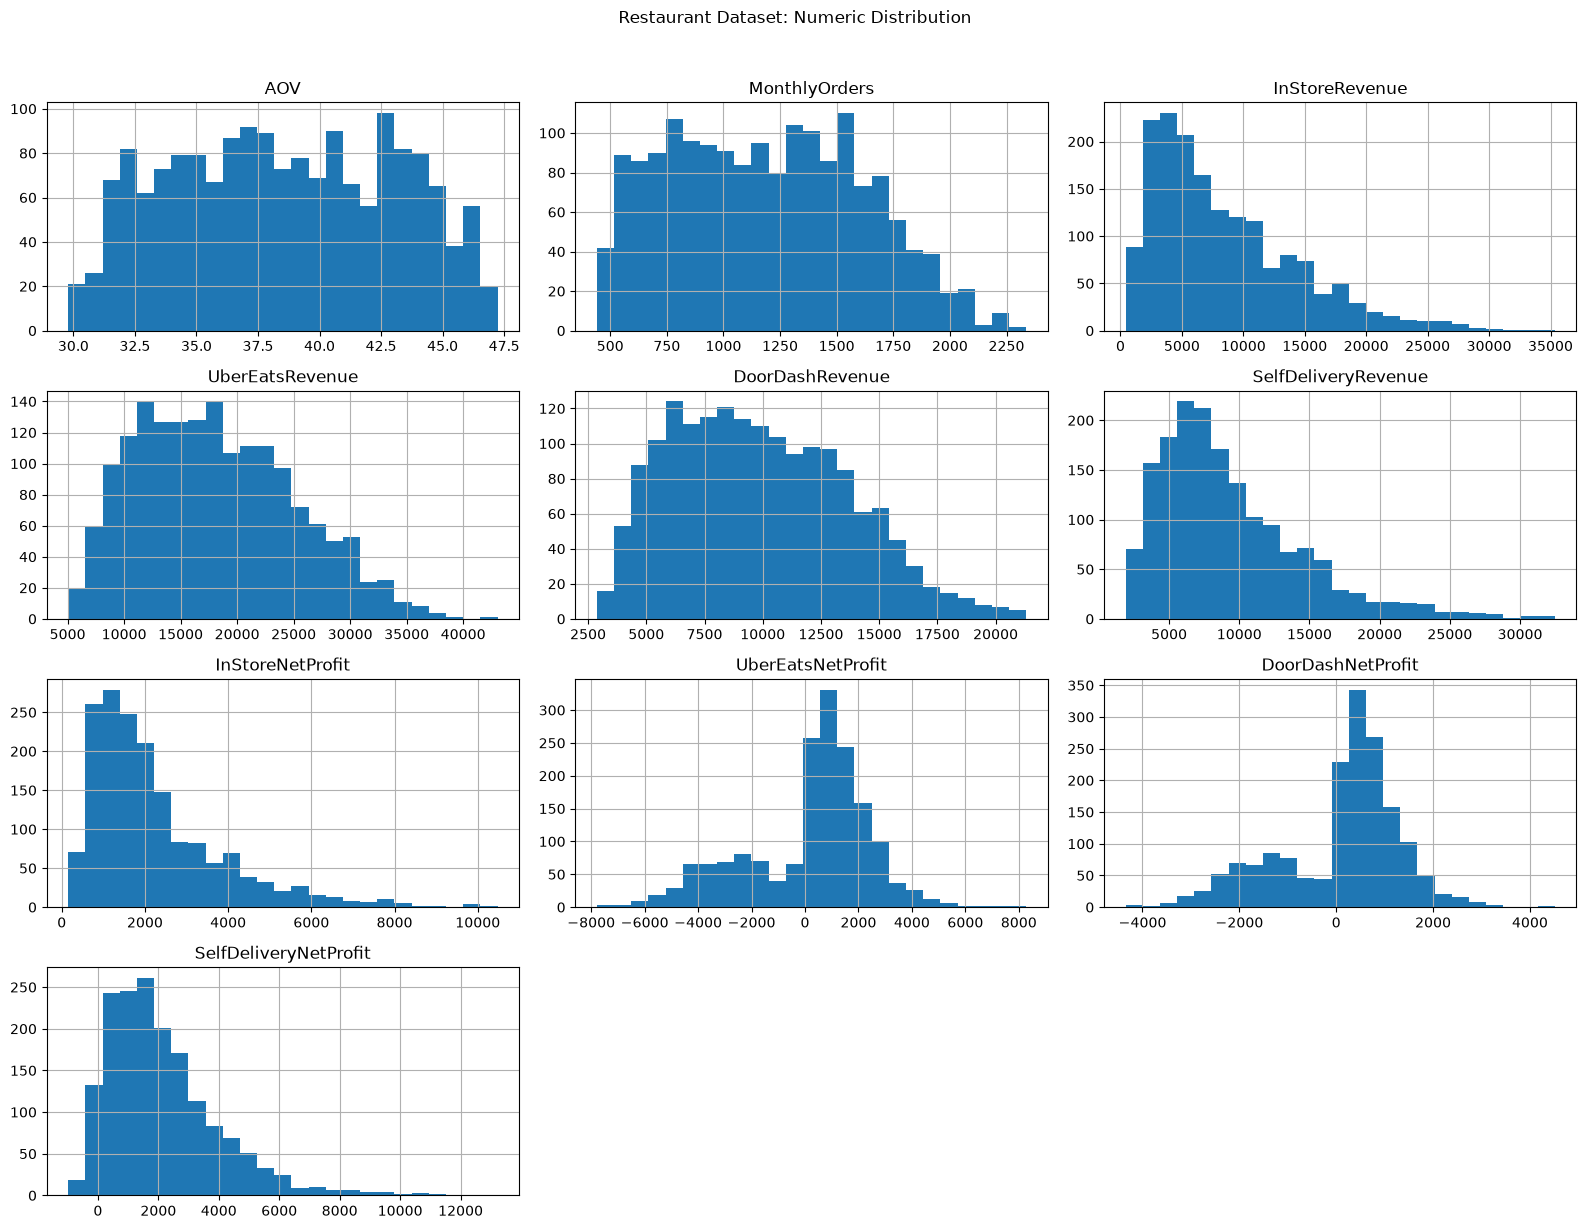

In [12]:
plot_cols = [
    "AOV",
    "MonthlyOrders",
    "InStoreRevenue",
    "UberEatsRevenue",
    "DoorDashRevenue",
    "SelfDeliveryRevenue",
    "InStoreNetProfit",
    "UberEatsNetProfit",
    "DoorDashNetProfit",
    "SelfDeliveryNetProfit"
]

df[plot_cols].hist(figsize=(16, 12), bins=25)
plt.suptitle("Restaurant Dataset: Numeric Distribution", y=1.02)
plt.tight_layout()
plt.show()

In [14]:
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "reports"

quality_report.to_csv(
    OUTPUT_DIR / "data_quality_report.csv"
    if False else OUTPUT_DIR / "data_quality_report.csv"
)

profit_validation.to_csv(
    OUTPUT_DIR / "profit_formula_validation.csv",
    index = False
)